# Clasificar flores Iris con vecinos cercanos

**Objetivo:** predecir la especie de una flor a partir de dos medidas del pétalo. Iris contiene 150 flores de tres especies: *setosa*, *versicolor* y *virginica*.

Usaremos **K vecinos más cercanos (KNN)**. Para clasificar una flor nueva, el modelo busca las 3 flores de entrenamiento más próximas y elige la especie mayoritaria. Con dos medidas podemos dibujar cada flor como un punto y ver la idea en un gráfico.

Ejecuta las celdas de arriba abajo.




## 1. Preparar las bibliotecas

`scikit-learn` contiene el conjunto de datos y el clasificador; `matplotlib` dibuja los gráficos. La celda siguiente instala ambas bibliotecas en el entorno del **kernel** de este notebook. Si se instala alguna por primera vez, reinicia el kernel y ejecuta las celdas de nuevo.

In [25]:
#Esto sólo haca falta lanzarlo una vez para instalar las librerías necesarias (por ejemplo, si estás usando un entorno virtual).  
# Por eso está comentado. Si es tu primera vez que ejecutas este script, descomenta la siguiente línea y ejecútala.:
# %pip install scikit-learn matplotlib

## 2. Cargar los datos

Cada fila de `X` representa una flor. Sus dos columnas son la **longitud** y la **anchura del pétalo**, medidas en centímetros. `y` contiene la especie correcta: 0, 1 o 2. Esos números corresponden, en orden, a los nombres de `iris.target_names`.

Elegimos solo dos de las cuatro medidas disponibles para poder mostrar las flores en un plano.

Usaremos iris domo Dataset:
- Aprende a leer y usar Iris Dataset: https://www.youtube.com/watch?v=6cXVi-bstps

In [26]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

iris = load_iris()
X = iris.data[:, 2:4]  # Columnas 2 y 3: longitud y anchura del pétalo.
y = iris.target       # Especie real de cada flor: 0, 1 o 2.
nombres = iris.target_names

print(f"Flores: {len(X)} | Medidas por flor: {X.shape[1]}")
print("Especies:", ", ".join(nombres))

Flores: 150 | Medidas por flor: 2
Especies: setosa, versicolor, virginica


## 3. Ver las flores

En este **diagrama de dispersión**, cada punto es una flor. La posición muestra sus dos medidas y el color indica su especie real. Las zonas donde se mezclan colores son las más difíciles de clasificar.

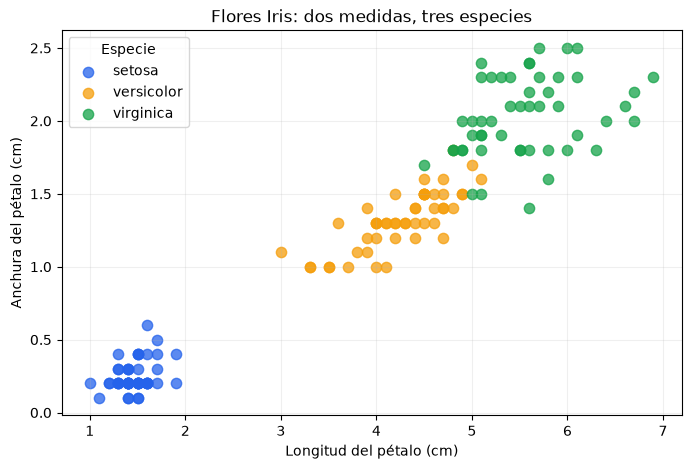

In [27]:
colores = ["#2563eb", "#f59e0b", "#16a34a"]

fig, ax = plt.subplots(figsize=(8, 5))
for clase, nombre in enumerate(nombres):
    flores = X[y == clase]  # Seleccionamos solo las flores de esta especie.
    ax.scatter(flores[:, 0], flores[:, 1], color=colores[clase],
               label=nombre, alpha=0.75, s=55)

ax.set(xlabel="Longitud del pétalo (cm)", ylabel="Anchura del pétalo (cm)",
       title="Flores Iris: dos medidas, tres especies")
ax.legend(title="Especie")
ax.grid(alpha=0.2)
plt.show()

## 4. Entrenar y evaluar el modelo

Separamos los datos: **80 % para entrenamiento** y **20 % para prueba**. El modelo aprende usando solo las flores de entrenamiento. Después predice las especies del grupo de prueba, que no ha visto al entrenar.

`stratify=y` mantiene aproximadamente la misma proporción de especies en ambos grupos. `random_state=42` hace que la separación sea reproducible. La **exactitud** es la proporción de predicciones correctas en el grupo de prueba.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

modelo = KNeighborsClassifier(n_neighbors=3)  # Votan las 3 flores más cercanas.
modelo.fit(X_train, y_train)                    # Usa solo las flores de entrenamiento.
predicciones = modelo.predict(X_test)          # Predice las flores reservadas para prueba.

aciertos = (predicciones == y_test).sum()
print(f"Aciertos: {aciertos} de {len(y_test)}")
print(f"Exactitud: {accuracy_score(y_test, predicciones):.1%}")

Aciertos: 29 de 30
Exactitud: 96.7%


## 5. Ver cómo decide una predicción

La **estrella roja** es la primera flor del grupo de prueba. Los **círculos negros** rodean a sus tres vecinos más cercanos del grupo de entrenamiento. El modelo predice la especie que aparece más veces entre esos vecinos. El color de los demás puntos indica su especie real.

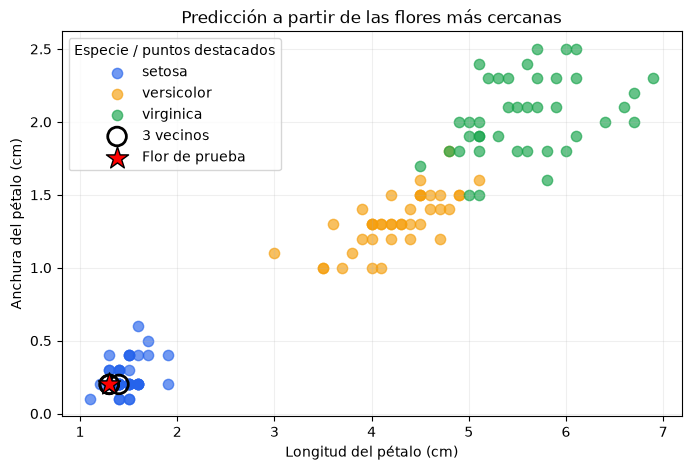

Especie real: setosa
Predicción:   setosa


In [29]:
indice = 0
flor = X_test[[indice]]  # Doble corchete: conservamos una matriz de 1 fila.
_, indices_vecinos = modelo.kneighbors(flor)
vecinos = X_train[indices_vecinos[0]]

fig, ax = plt.subplots(figsize=(8, 5))
for clase, nombre in enumerate(nombres):
    flores = X_train[y_train == clase]
    ax.scatter(flores[:, 0], flores[:, 1], color=colores[clase],
               label=nombre, alpha=0.65, s=55)

# Rodeamos los tres puntos que participan en la votación.
ax.scatter(vecinos[:, 0], vecinos[:, 1], facecolors="none",
           edgecolors="black", linewidths=2, s=180, label="3 vecinos")
ax.scatter(flor[0, 0], flor[0, 1], color="red", marker="*",
           edgecolors="black", s=280, label="Flor de prueba", zorder=5)

ax.set(xlabel="Longitud del pétalo (cm)", ylabel="Anchura del pétalo (cm)",
       title="Predicción a partir de las flores más cercanas")
ax.legend(title="Especie / puntos destacados")
ax.grid(alpha=0.2)
plt.show()

print(f"Especie real: {nombres[y_test[indice]]}")
print(f"Predicción:   {nombres[predicciones[indice]]}")

## 6. Ver todos los aciertos y errores

La **matriz de confusión** resume las 30 flores de prueba. Cada fila representa una especie real y cada columna una predicción. Los números de la diagonal son aciertos; los números fuera de ella son confusiones entre especies.

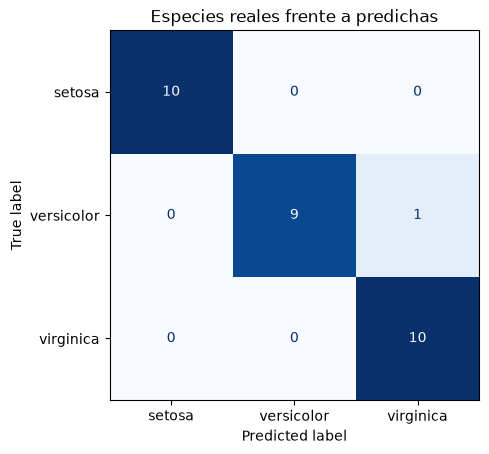

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones, display_labels=nombres,
    cmap="Blues", colorbar=False
)
plt.title("Especies reales frente a predichas")
plt.show()

## Para experimentar

Cambia `n_neighbors=3` por `1` o `5` y vuelve a ejecutar desde la sección 4. Observa si cambia la exactitud y qué vecinos rodean la estrella. Después prueba otro valor de `random_state` para usar una separación distinta de entrenamiento y prueba.